In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from dataset.dataset import load_data
from softmax_CBM.dataset.dataset import load_data as load_data_softmax
from dataset.utils import *
import matplotlib.pyplot as plt

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("Device:", device, torch.cuda.get_device_name(0))
else:
    print("Device:", device)

Device: cuda:0 NVIDIA GeForce GTX 1650 Ti


In [3]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts



N_CONCEPT = 17
N_CLASSES = 52
val_loader = load_data("./dataset/playing-cards/splits/single/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/playing-cards/", return_orig=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/playing-cards/splits/single/concepts.txt")


"""
N_CONCEPT = 52
N_CLASSES = 1
val_loader = load_data("./dataset/three_card_poker/val.pkl", 16, dataset_root="./dataset/three_card_poker", has_class=False, return_orig=True)

concept_index_to_string = IndexToString("./dataset/three_card_poker/concepts.txt")
"""

XtoC = PlayingCardNet(num_classes=N_CONCEPT)
XtoC.load_state_dict(torch.load("./saves/XtoC_single_converted.pth"))
XtoC.to(device)
XtoC.eval()

print("model loaded")

model loaded


In [3]:
##### https://github.com/fhvilshoj/TorchLRP/blob/74253a1be05f0be0b7c535736023408670443b6e/examples/visualization.py#L60
def heatmap(X, cmap_name="seismic"):
	cmap = plt.cm.get_cmap(cmap_name)

	if X.shape[1] in [1, 3]:  # move channel index to end + convert to np array
		X = X.permute(0, 2, 3, 1).detach().cpu().numpy()
	if isinstance(X, torch.Tensor):  # convert tensor to np array
		X = X.detach().cpu().numpy()

	shape = X.shape
	tmp = X.sum(axis=-1) # Reduce channel axis

	tmp = project(tmp, output_range=(0, 255)).astype(int)
	tmp = cmap(tmp.flatten())[:, :3].T
	tmp = tmp.T

	shape = list(shape)
	shape[-1] = 3
	return tmp.reshape(shape).astype(np.float32)


def project(X, output_range=(0, 1)):
	absmax = np.abs(X).max(axis=tuple(range(1, len(X.shape))), keepdims=True)
	X /= absmax + (absmax == 0).astype(float)
	X = (X+1) / 2. # range [0, 1]
	X = output_range[0] + X * (output_range[1] - output_range[0]) # range [x, y]
	return X

In [5]:
XtoC = convert(XtoC).to(device)

print(XtoC)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Conv2d(256, 512, kernel_si

## Show true concepts and classification + predicted concepts and classification

True image size (channels, width, height): torch.Size([3, 299, 299])
True  image concepts: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 1., 0., 0.])


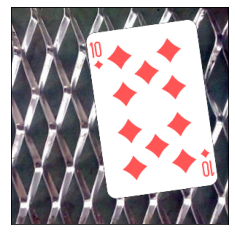

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


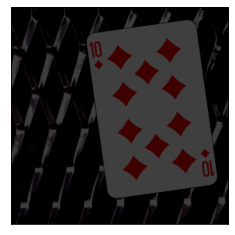

In [6]:
imageId = 7

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [7]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoC(image)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

Predicted concepts: tensor([[    0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     1.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     1.0000,     0.0000,     0.0000]],
       device='cuda:0', grad_fn=<SigmoidBackward0>)
id: 9, concept name: 10, sig value: 1.0
id: 14, concept name: D, sig value: 1.0


## Generate LRP saliency maps for concepts using a single rule

A


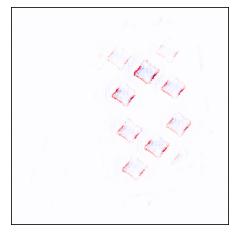

2


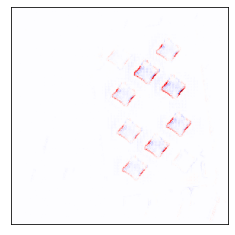

3


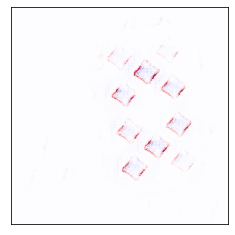

4


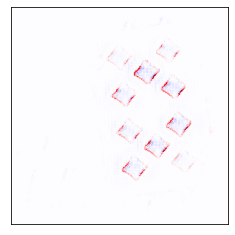

5


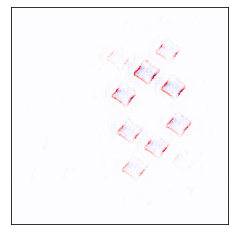

6


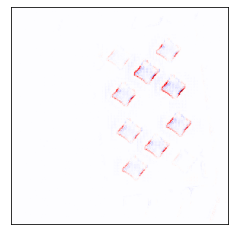

7


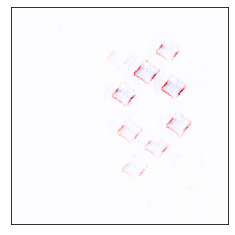

8


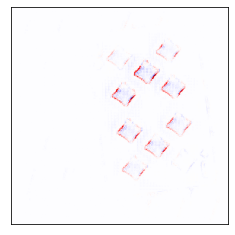

9


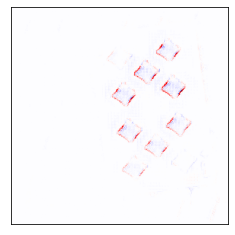

10


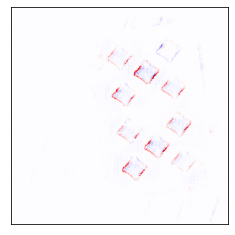

J


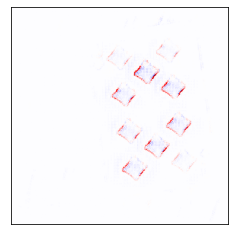

Q


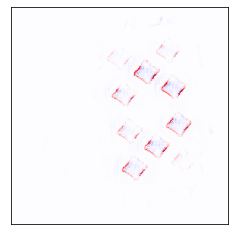

K


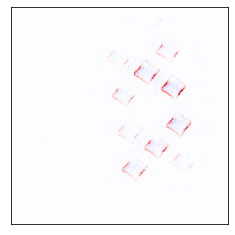

H


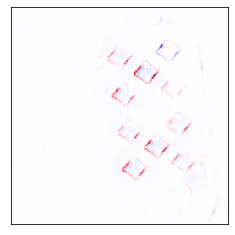

D


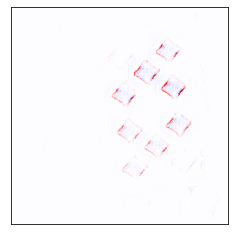

C


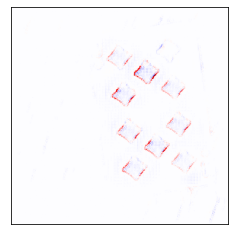

S


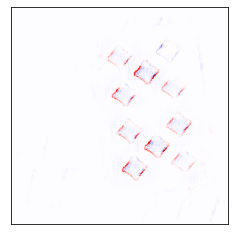

In [8]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

#pred_concepts = XtoC.forward(image, explain=True, rule="alpha1beta0")
pred_concepts = XtoC.forward(image, explain=True, rule="alpha2beta1")
#pred_concepts = XtoC.forward(image, explain=True, rule="epsilon")
#pred_concepts = XtoC.forward(image, explain=True, rule="gradient")

# get saliecy maps for each concept
for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(concept_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    #plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close()

## Generate LRP saliency maps for concepts using composite rules

In [9]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 15:
        XtoC_model_1.append(m)
    elif idx < 29:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device)
XtoC_model_2.to(device)
XtoC_model_3.to(device)

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(256, 5

A


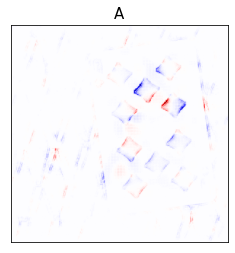

2


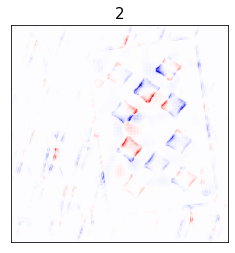

3


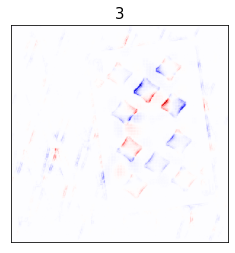

4


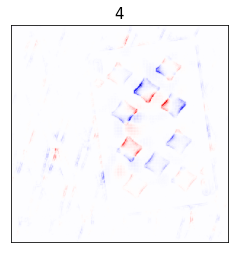

5


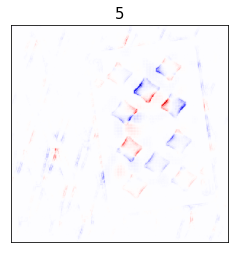

6


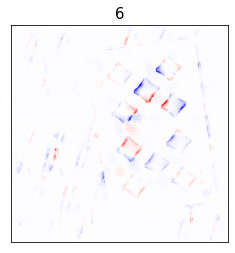

7


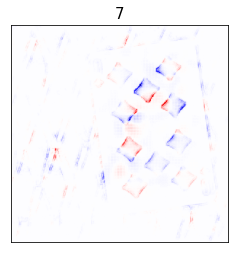

8


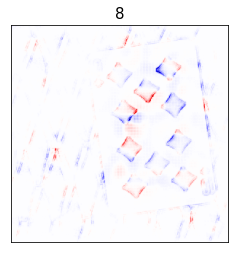

9


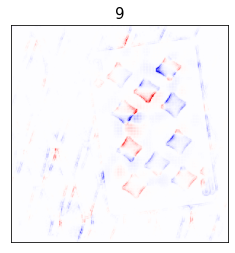

10


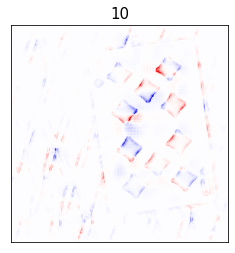

J


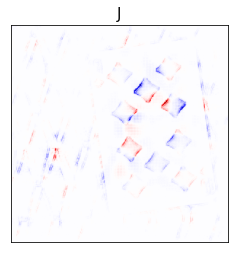

Q


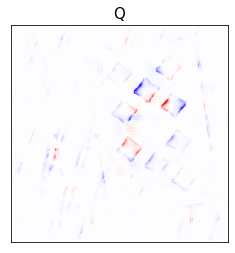

K


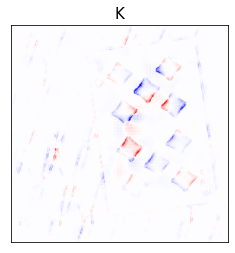

H


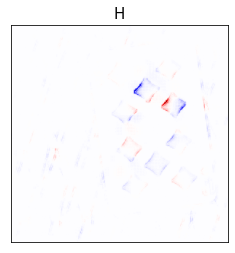

D


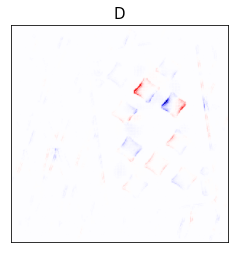

C


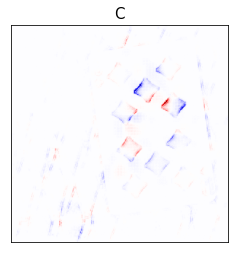

S


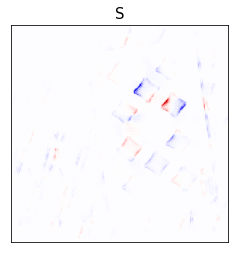

In [10]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")
    
# get saliecy maps for top 5 concepts
pred_precent_concepts = []
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        pred_precent_concepts.append((idx, i.item()))

pred_precent_concepts = sorted(pred_precent_concepts, key=lambda x: -x[1])

for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(concept_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close() 


# multi card input model


In [11]:
NUM_IMG_OUTPUT = 3
USE_SIG = True

In [12]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts or 17 if using suit and value



N_CONCEPT = 52
N_CLASSES = 6
val_loader = load_data("./dataset/individual_three_card_poker/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/individual_three_card_poker", return_orig=True, multi_image=True, shuffle=True)
#val_loader = load_data_softmax("./softmax_CBM/dataset/individual_three_card_poker/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./softmax_CBM/dataset/individual_three_card_poker", return_orig=True, multi_image=True, shuffle=True)


#concept_index_to_string = IndexToString("./dataset/individual_three_card_poker/card_concepts.txt")
concept_index_to_string = IndexToString("./dataset/individual_three_card_poker/card_classes.txt")
class_index_to_string = IndexToString("./dataset/individual_three_card_poker/hand_classes.txt")

XtoCtoY = End2EndModel(num_classes=N_CLASSES, num_concepts=N_CONCEPT, num_images_per_output=NUM_IMG_OUTPUT, use_sigmoid=USE_SIG, use_modulelist=False)
#XtoCtoY.load_state_dict(torch.load("./saves/softmax_XtoCtoY_best.pth", map_location=torch.device('cpu')))
XtoCtoY.load_state_dict(torch.load("./saves/3_image_XtoCtoY_converted.pth", map_location=torch.device('cpu')))
XtoCtoY.to(device)
XtoCtoY.eval()

print("model loaded")

RuntimeError: Error(s) in loading state_dict for End2EndModel:
	Missing key(s) in state_dict: "x_to_c_model.features.11.weight", "x_to_c_model.features.11.bias", "x_to_c_model.features.12.running_mean", "x_to_c_model.features.12.running_var", "x_to_c_model.features.15.weight", "x_to_c_model.features.15.bias", "x_to_c_model.features.16.weight", "x_to_c_model.features.16.bias", "x_to_c_model.features.16.running_mean", "x_to_c_model.features.16.running_var", "x_to_c_model.features.18.weight", "x_to_c_model.features.18.bias", "x_to_c_model.features.19.weight", "x_to_c_model.features.19.bias", "x_to_c_model.features.19.running_mean", "x_to_c_model.features.19.running_var", "x_to_c_model.features.22.weight", "x_to_c_model.features.22.bias", "x_to_c_model.features.23.weight", "x_to_c_model.features.23.bias", "x_to_c_model.features.23.running_mean", "x_to_c_model.features.23.running_var", "x_to_c_model.features.25.weight", "x_to_c_model.features.25.bias", "x_to_c_model.features.26.weight", "x_

In [13]:
XtoC = convert(XtoCtoY.x_to_c_model).to(device)
CtoY = convert(XtoCtoY.c_to_y_model).to(device)

print(XtoC)
print(CtoY)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Conv2d(256, 512, kernel_si

True image size (channels, width, height): torch.Size([3, 3, 299, 299])
True  image concepts: tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])


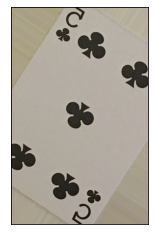

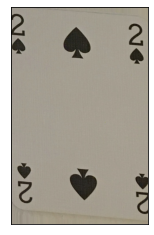

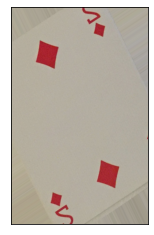

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


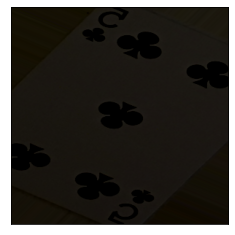

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


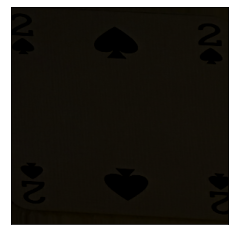

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


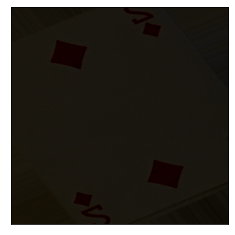

In [14]:
imageId = 7

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

concepts[imageId] = concepts[imageId].view(3, -1)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])


for i in range(images.size(1)):

    plt.xticks([])
    plt.yticks([])
    plt.imshow(original_imgs[imageId][i, :, :, :].squeeze().permute(1, 2, 0))
    plt.show()

for i in range(images.size(1)):

    plt.xticks([])
    plt.yticks([])
    plt.imshow(images[imageId][i, :, :, :].squeeze().permute(1, 2, 0))
    plt.show()

In [15]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoCtoY(image)

concept_out = prediction[0]
task_out = prediction[1]

_, task_out = task_out.max(1)

concept_out = concept_out.view(3, -1)

for i in range(concept_out.size(0)):
    pred_concepts_readable = torch.nn.Sigmoid()(concept_out[i])
    print("Predicted concepts:", pred_concepts_readable)

    # print concept as string if prediction is >= 0.5
    for idx, i in enumerate(pred_concepts_readable):
        if i.item() >= 0.5:
            print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")
        
print("Class out:", class_index_to_string(task_out.item()))

RuntimeError: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same

In [16]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)

if NUM_IMG_OUTPUT != 1:
    # split batch into first hand card, second hand card etc.
    # Run each card batch seperatly
    split_images = []
    for image_id in range(image.size(1)):
        split_images.append(image[:, image_id, :, : , :])
else:
    split_images = [image]  # make sure input is in same format as is there are multiple inputs

outputs = []
for image in split_images:
    image.requires_grad_(True)
    image.grad = None  # Reset gradient
    outputs.append(XtoC.forward(image, explain=True, rule="alpha1beta0"))
    # alpha1beta0, alpha2beta1, epsilon, gradient
    




for idx, pred_concepts in enumerate(outputs):

    # get saliecy maps for each concept
    for i in range(pred_concepts.size(1)):
        filter_out = torch.zeros_like(pred_concepts)
        filter_out[:,i] += 1

        # Get the gradient of each input
        image_gradient = torch.autograd.grad(
            pred_concepts,
            split_images[idx],
            grad_outputs=filter_out,
            retain_graph=True)[0]


        attr = heatmap(image_gradient, cmap_name='seismic')

        print(concept_index_to_string(i))

        plt.xticks([])
        plt.yticks([])
        #plt.title(label=concept_index_to_string(i), fontsize=15)
        plt.imshow(attr.squeeze(), cmap='seismic')
        #plt.savefig(f'temp/{i}.png')
        plt.show()

        plt.close()

RuntimeError: CUDA out of memory. Tried to allocate 392.00 MiB (GPU 0; 3.82 GiB total capacity; 2.57 GiB already allocated; 157.44 MiB free; 2.62 GiB reserved in total by PyTorch) If reserved memory is >> allocated memory try setting max_split_size_mb to avoid fragmentation.  See documentation for Memory Management and PYTORCH_CUDA_ALLOC_CONF

In [17]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 11:
        XtoC_model_1.append(m)
    elif idx < 15:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device)
XtoC_model_2.to(device)
XtoC_model_3.to(device)

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
)
Sequential(
  (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Con

In [18]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)

if NUM_IMG_OUTPUT != 1:
    # split batch into first hand card, second hand card etc.
    # Run each card batch seperatly
    split_images = []
    for image_id in range(image.size(1)):
        split_images.append(image[:, image_id, :, : , :])
else:
    split_images = [image]  # make sure input is in same format as is there are multiple inputs

outputs = []
for image in split_images:
    image.requires_grad_(True)
    image.grad = None  # Reset gradient
    output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
    output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
    outputs.append(XtoC_model_3.forward(output_2, explain=True, rule="gradient"))
    




for idx, pred_concepts in enumerate(outputs):

    # get saliecy maps for each concept
    for i in range(pred_concepts.size(1)):
        filter_out = torch.zeros_like(pred_concepts)
        filter_out[:,i] += 1

        # Get the gradient of each input
        image_gradient = torch.autograd.grad(
            pred_concepts,
            split_images[idx],
            grad_outputs=filter_out,
            retain_graph=True)[0]


        attr = heatmap(image_gradient, cmap_name='seismic')

        plt.xticks([])
        plt.yticks([])
        plt.title(label=concept_index_to_string(i), fontsize=15)
        plt.imshow(attr.squeeze(), cmap='seismic')
        plt.savefig(f'temp/{idx}-{i}.png')
        plt.show()

        plt.close()

RuntimeError: CUDA out of memory. Tried to allocate 392.00 MiB (GPU 0; 3.82 GiB total capacity; 2.48 GiB already allocated; 157.44 MiB free; 2.62 GiB reserved in total by PyTorch) If reserved memory is >> allocated memory try setting max_split_size_mb to avoid fragmentation.  See documentation for Memory Management and PYTORCH_CUDA_ALLOC_CONF

# multi card input model with one image per output


In [4]:
NUM_IMG_OUTPUT = 1
USE_SIG = True

In [5]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts or 17 if using suit and value



N_CONCEPT = 52
N_CLASSES = 1
val_loader = load_data("./dataset/playing-cards/splits/three_card_class/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/playing-cards/", return_orig=True, shuffle=True)


concept_index_to_string = IndexToString("./dataset/playing-cards/splits/three_card_class/concepts.txt")
class_index_to_string = IndexToString("./dataset/playing-cards/splits/three_card_class/classes.txt")

"""
XtoCtoY = End2EndModel(num_classes=N_CLASSES, num_concepts=N_CONCEPT, num_images_per_output=NUM_IMG_OUTPUT, use_sigmoid=USE_SIG, use_modulelist=False)
XtoCtoY.load_state_dict(torch.load("./saves/XtoCtoY_converted.pth", map_location=torch.device('cpu')))
XtoCtoY.to(device)
XtoCtoY.eval()
"""

XtoC = PlayingCardNet(num_classes=N_CONCEPT)
XtoC.load_state_dict(torch.load("./saves/XtoC_three_converted.pth"))
XtoC.to(device)
XtoC.eval()

print("model loaded")

model loaded


In [6]:
#XtoC = convert(XtoCtoY.x_to_c_model).to(device)
#CtoY = convert(XtoCtoY.c_to_y_model).to(device)

XtoC = convert(XtoC).to(device)

print(XtoC)
#print(CtoY)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Conv2d(256, 512, kernel_si

True image size (channels, width, height): torch.Size([3, 299, 299])
True  image concepts: tensor([0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


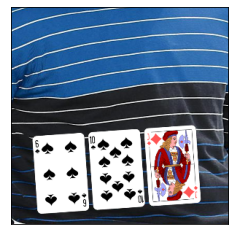

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


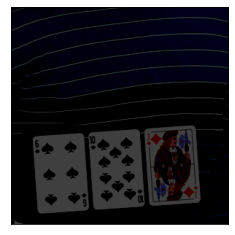

In [33]:
imageId = 1

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [34]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoC(image)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

Predicted concepts: tensor([[    0.0000,     0.0000,     0.0000,     1.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     1.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0007,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     1.0000,
             0.0001,     0.0000,     0.0000,     0.0054,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000]], device='cuda:0',
       grad_fn=<SigmoidBackward0>)
id: 3, concept name: 10S, sig value: 1.0
id: 23, concept name: 6S, sig value: 1.0
id: 41, concept name: JD, sig value: 0.9999995231628418


10C


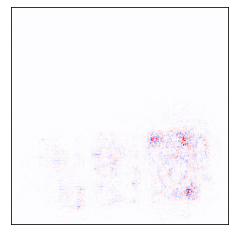

10D


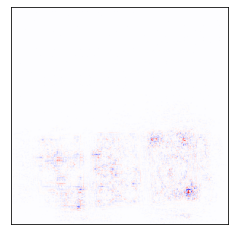

10H


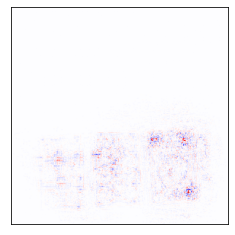

10S


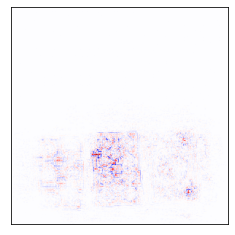

2C


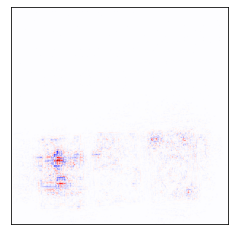

2D


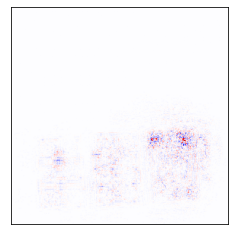

2H


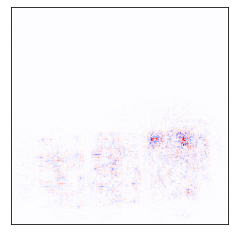

2S


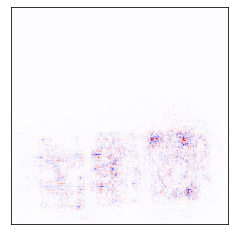

3C


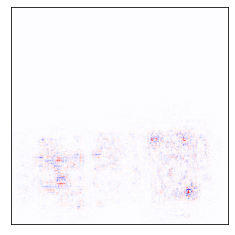

3D


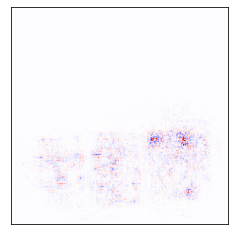

3H


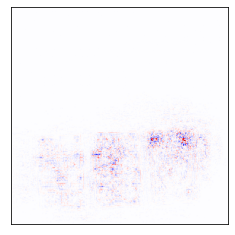

3S


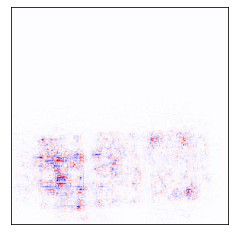

4C


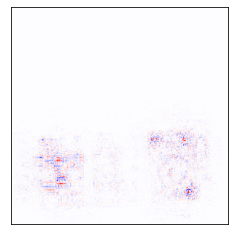

4D


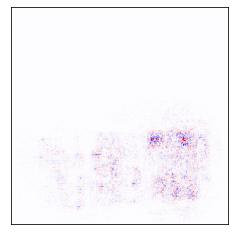

4H


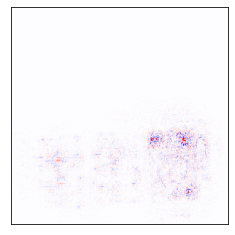

4S


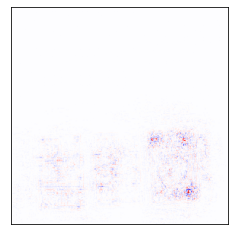

5C


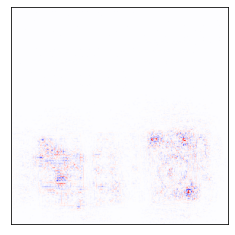

5D


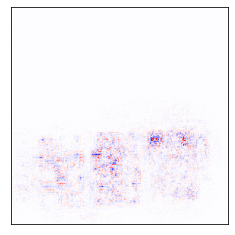

5H


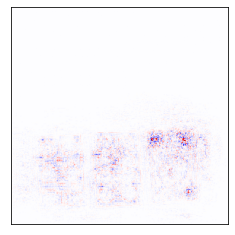

5S


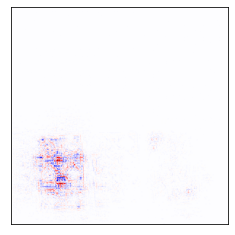

6C


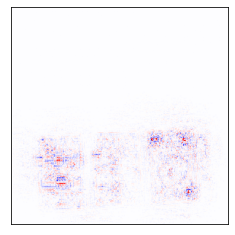

6D


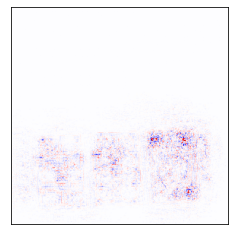

6H


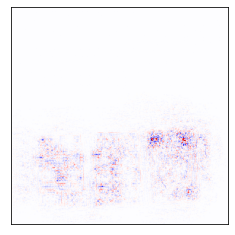

6S


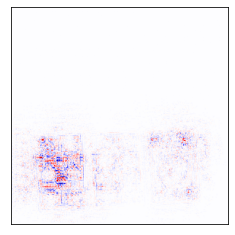

7C


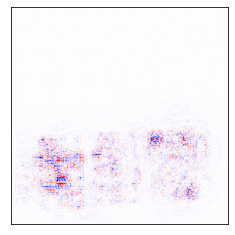

7D


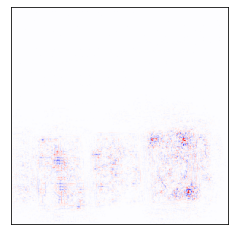

7H


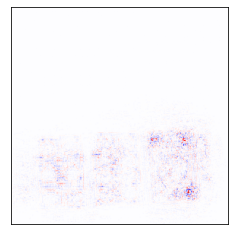

7S


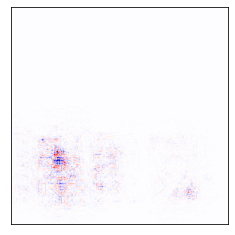

8C


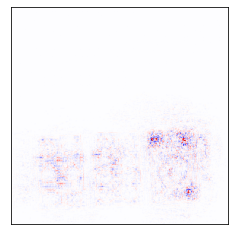

8D


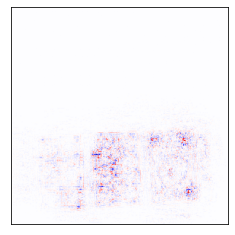

8H


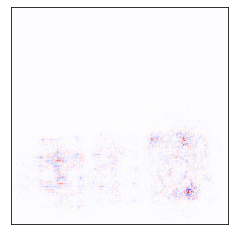

8S


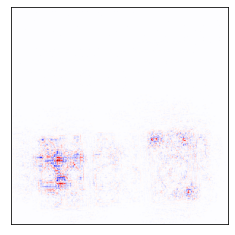

9C


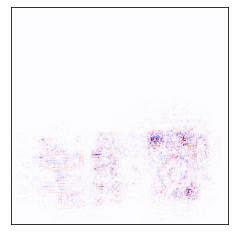

9D


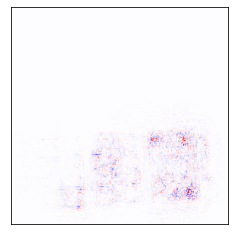

9H


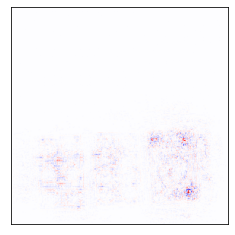

9S


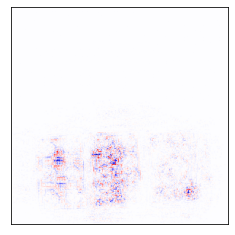

AC


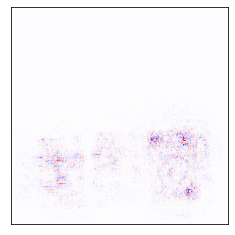

AD


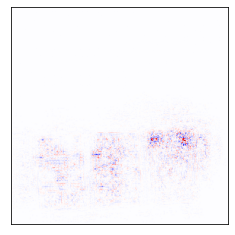

AH


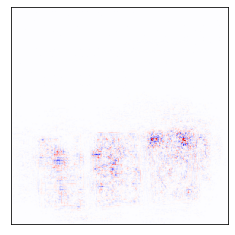

AS


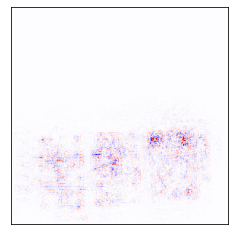

JC


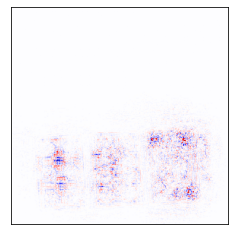

JD


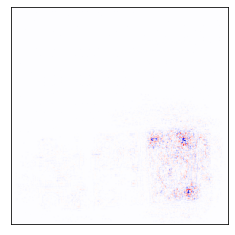

JH


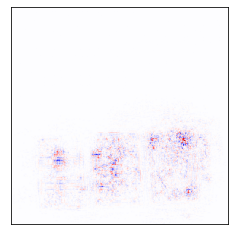

JS


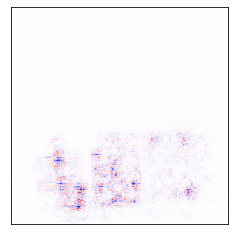

KC


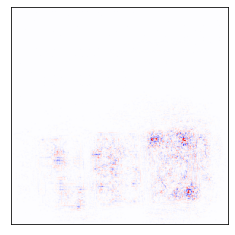

KD


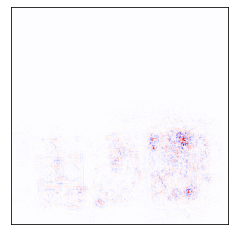

KH


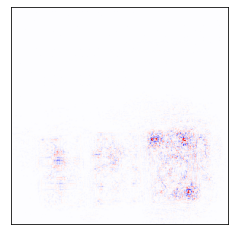

KS


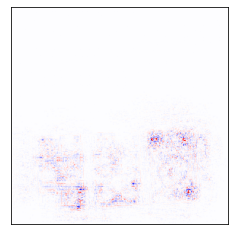

QC


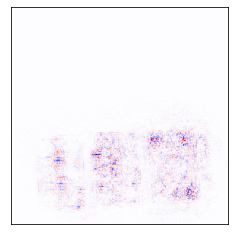

QD


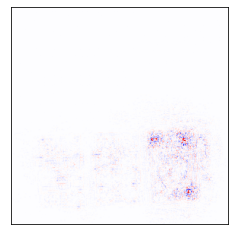

QH


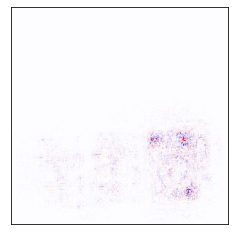

QS


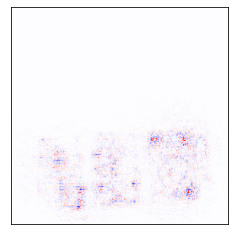

In [35]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

pred_concepts = XtoC.forward(image, explain=True, rule="gradient")
# alpha1beta0 alpha2beta1 epsilon gradient

# get saliecy maps for each concept
for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(concept_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    #plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close()

In [36]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 15:
        XtoC_model_1.append(m)
    elif idx < 29:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device)
XtoC_model_2.to(device)
XtoC_model_3.to(device)

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(256, 5

10C


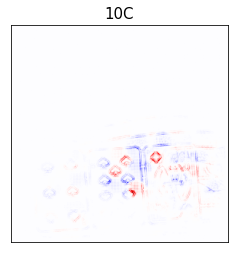

10D


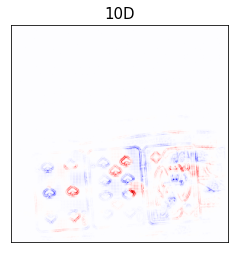

10H


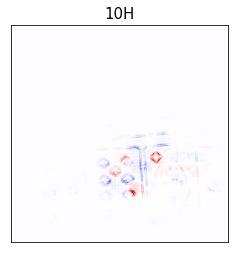

10S


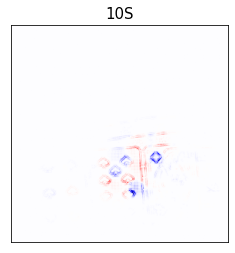

2C


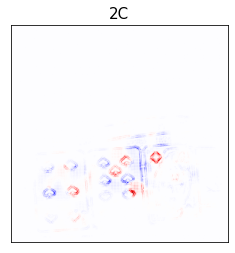

2D


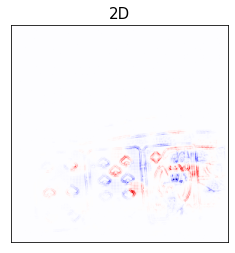

2H


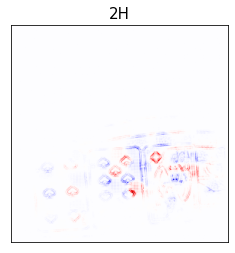

2S


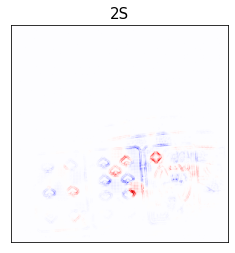

3C


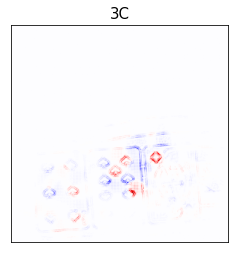

3D


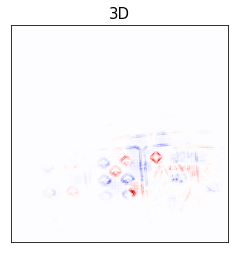

3H


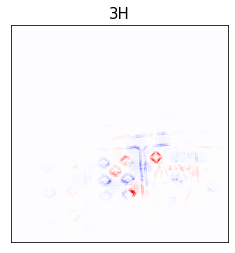

3S


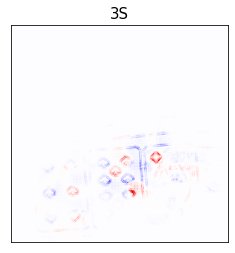

4C


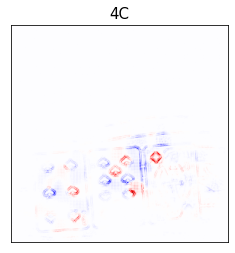

4D


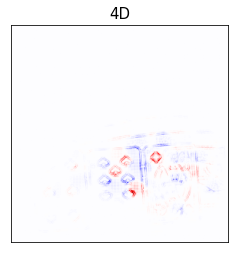

4H


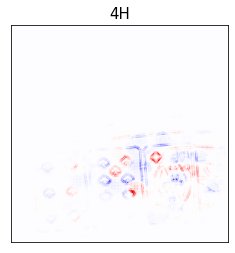

4S


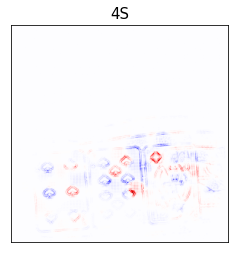

5C


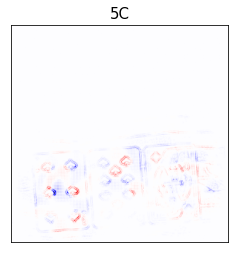

5D


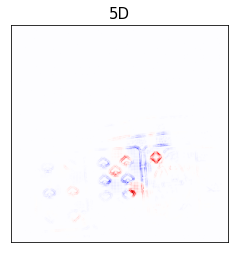

5H


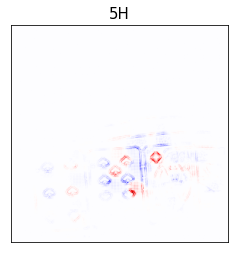

5S


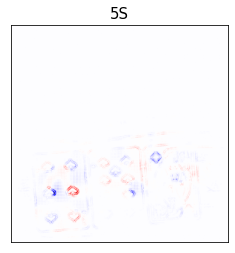

6C


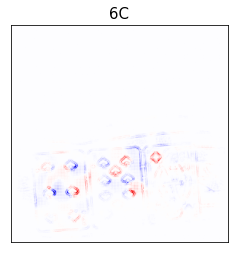

6D


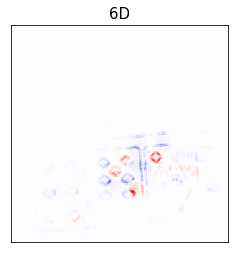

6H


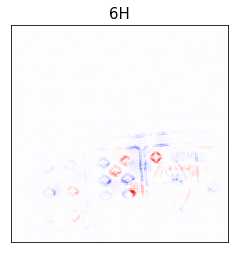

6S


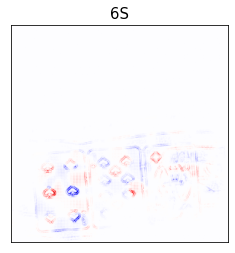

7C


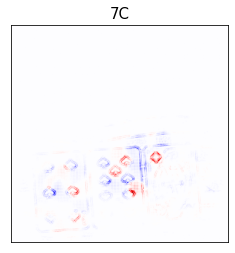

7D


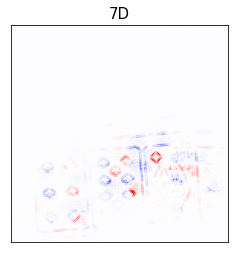

7H


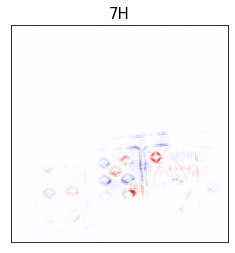

7S


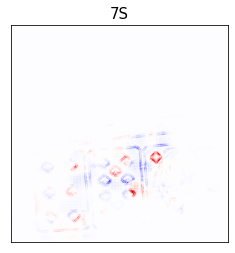

8C


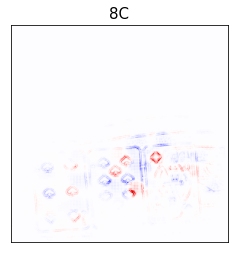

8D


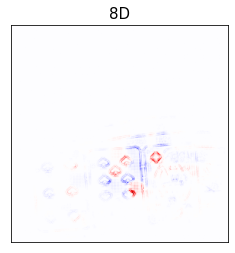

8H


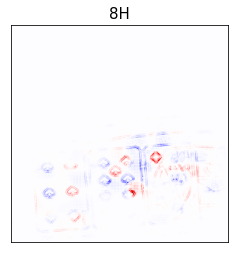

8S


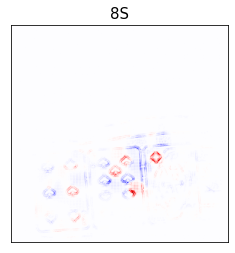

9C


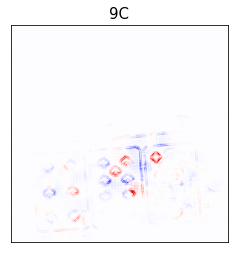

9D


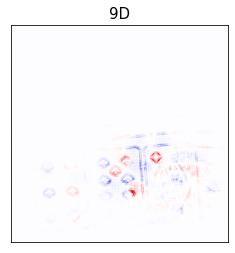

9H


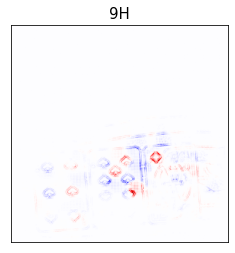

9S


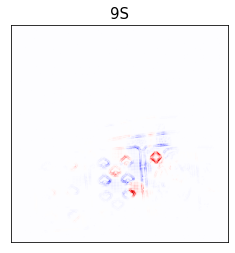

AC


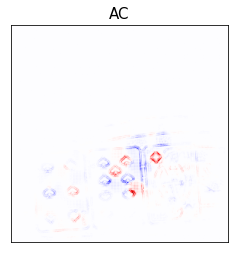

AD


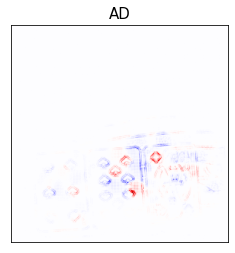

AH


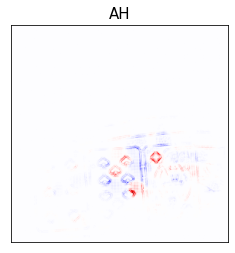

AS


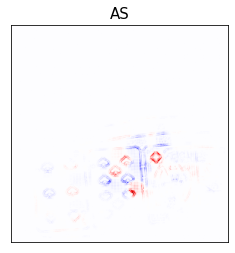

JC


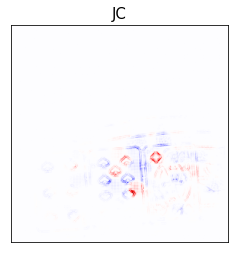

JD


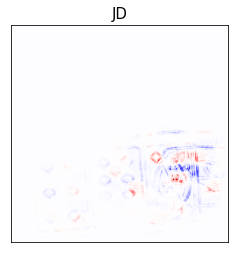

JH


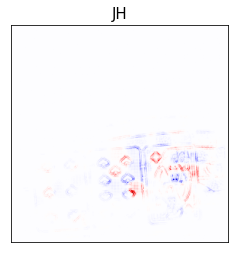

JS


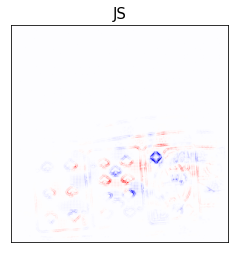

KC


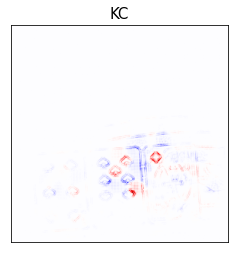

KD


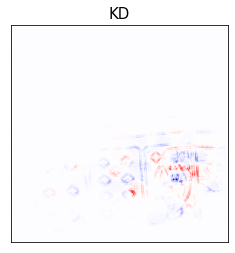

KH


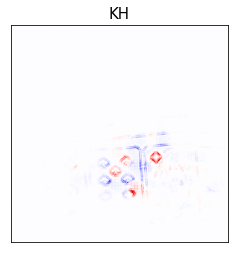

KS


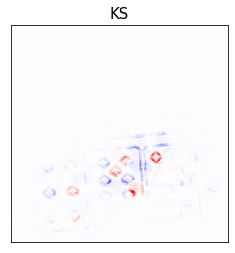

QC


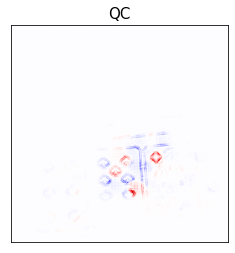

QD


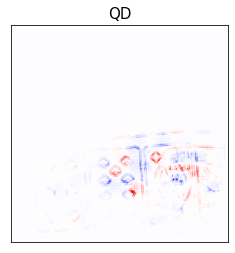

QH


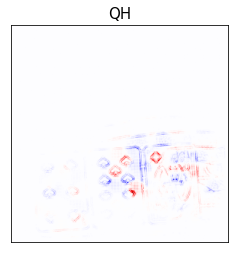

QS


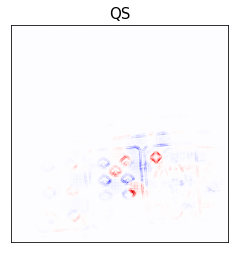

In [37]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")
    
    
# get saliecy maps for top 5 concepts
pred_precent_concepts = []
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        pred_precent_concepts.append((idx, i.item()))

pred_precent_concepts = sorted(pred_precent_concepts, key=lambda x: -x[1])

for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')
    
    print(concept_index_to_string(i))

    plt.xticks([])
    plt.yticks([])
    plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close() 
